<a href="https://colab.research.google.com/github/Arsalan-Ahmad5/VisionCart_project/blob/main/PREDICTION_MODEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Mon Oct 12 03:52:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'merged_data_yolo26_detection_clean.zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/merged_data_yolo26_detection_clean.zip"
extract_path = "/content/grocery_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['README.roboflow.txt', 'test', 'valid', 'train', 'data.yaml']


In [ ]:
from pathlib import Path

data_yaml = Path("/content/grocery_dataset/data.yaml")

print(data_yaml.read_text())

train: ../train/images
val: ../valid/images
test: ../test/images
nc: 4
names:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee



In [ ]:
from pathlib import Path

data_yaml = Path("/content/grocery_dataset/data.yaml")

data_yaml.write_text("""train: train/images
val: valid/images
test: test/images

nc: 4
names:
  - Maggi
  - OREO BISCUIT
  - Sensodyne
  - Yippee
""")

print(data_yaml.read_text())

train: train/images
val: valid/images
test: test/images

nc: 4
names:
  - Maggi
  - OREO BISCUIT
  - Sensodyne
  - Yippee



In [ ]:
from pathlib import Path

root = Path("/content/grocery_dataset")

for split in ["train", "valid", "test"]:
    images = list((root / split / "images").glob("*"))
    labels = list((root / split / "labels").glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    extra_labels = label_stems - image_stems

    print(f"\n{split.upper()}")
    print(f"Images: {len(images)}")
    print(f"Labels: {len(labels)}")
    print(f"Missing labels: {len(missing_labels)}")
    print(f"Extra labels: {len(extra_labels)}")


TRAIN
Images: 1644
Labels: 1644
Missing labels: 0
Extra labels: 0

VALID
Images: 157
Labels: 157
Missing labels: 0
Extra labels: 0

TEST
Images: 78
Labels: 78
Missing labels: 0
Extra labels: 0


In [ ]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00


In [ ]:
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo26s.pt")

print("YOLO26-S loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
YOLO26-S loaded successfully!


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")

results = model.train(
    data="/content/grocery_dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    patience=20,
    project="/content/runs",
    name="grocery_yolo26s",
    pretrained=True
)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/grocery_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=grocery_yolo26s, nbs=64, nms=None, opset=None, optimi

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/grocery_yolo26s/weights/best.pt")

test_results = model.val(
    data="/content/grocery_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0
)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 13.3±8.9 MB/s, size: 31.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/grocery_dataset/test/labels... 78 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 78/78 439.9it/s 0.2s
val: New cache created: /content/grocery_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.2s
                   all         78         96      0.998          1      0.995      0.898
                 Maggi         24         28      0.996          1      0.995      0.863
          OREO BISCUIT         19         19          1          1      0.995      0.925
        

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/grocery_yolo26s/weights/best.pt")

results = model.predict(
    source="/content/Oreo-biscuits.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

print("Prediction completed.")


image 1/1 /content/Oreo-biscuits.jpg: 640x640 1 OREO BISCUIT, 1 Sensodyne, 16.1ms
Speed: 2.1ms preprocess, 16.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction completed.


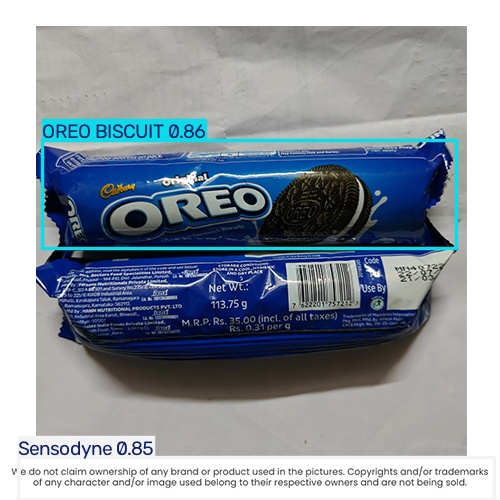

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/runs/detect/predict/Oreo-biscuits.jpg"))

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/grocery_yolo26s/weights/best.pt")

results = model.predict(
    source="/content/yippie2.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

print("Testing completed.")


image 1/1 /content/yippie2.jpg: 384x640 1 Yippee, 17.6ms
Speed: 2.3ms preprocess, 17.6ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict-2
Testing completed.


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/grocery_yolo26s/weights/best.pt")

results = model.predict(
    source="/content/maggi1.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

print("Testing completed.")


image 1/1 /content/maggi1.jpg: 640x640 1 Maggi, 17.8ms
Speed: 5.6ms preprocess, 17.8ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3
Testing completed.


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/grocery_yolo26s/weights/best.pt")

results = model.predict(
    source="/content/ore1.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

print("Testing completed.")


image 1/1 /content/ore1.jpg: 640x640 1 Sensodyne, 16.2ms
Speed: 2.5ms preprocess, 16.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-5
Testing completed.


In [ ]:
from google.colab import files

files.download("/content/runs/grocery_yolo26s/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
files.download("/content/runs/grocery_yolo26s/weights/last.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MODEL RE OPENING ON NEW SESSION

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'best (1).pt', 'sample_data']


In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/best (1).pt"

print("Exists:", os.path.exists(model_path))
print("Size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

model = YOLO(model_path)
print("Model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Exists: True
Size: 19.37 MB
Model loaded successfully!


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/best (1).pt")

results = model.predict(
    source="/content/maggi2.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

print("Prediction completed.")


image 1/1 /content/maggi2.jpg: 480x640 1 Maggi, 18.3ms
Speed: 97.4ms preprocess, 18.3ms inference, 36.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict
Prediction completed.


INTEGRATING VLM FOR BETTERMENT


In [ ]:
!pip install -U transformers accelerate qwen-vl-utils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 105.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 24.7 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.18.0
    Uninstalling transformers-5.18.0:
      Successfully uninstalled transformers-5.18.0


In [ ]:
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct",
    torch_dtype=torch.float16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct"
)

print("✅ Qwen3-VL-4B loaded successfully!")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

✅ Qwen3-VL-4B loaded successfully!


In [ ]:
from PIL import Image

image_path = "/content/maggi2.jpg"

img = Image.open(image_path)
print("Image loaded successfully:", img.size)

Image loaded successfully: (1500, 1055)


In [ ]:
from qwen_vl_utils import process_vision_info

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": "/content/maggi2.jpg",
            },
            {
                "type": "text",
                "text": """Identify the grocery product visible in this image.

Choose ONLY one:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

Look carefully at the product's logo, text, packaging and visual appearance.
Do not guess.
Return exactly:
Product: <one class>
Reason: <short explanation>"""
            }
        ],
    }
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
).to(model.device)

generated_ids = model.generate(
    **inputs,
    max_new_tokens=100
)

generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]

output = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)

print(output[0])

Product: Maggi
Reason: The packaging clearly displays the "Maggi" logo and "2-Minute Noodles" text, along with the "Masala Taste" variant, matching the product in the image.


In [ ]:
from ultralytics import YOLO

yolo_model = YOLO("/content/best (1).pt")

results = yolo_model.predict(
    source="/content/maggi2.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

for result in results:
    print("\nYOLO detections:")

    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        class_name = result.names[cls_id]

        print(f"  {class_name}: {conf:.3f}")


image 1/1 /content/maggi2.jpg: 480x640 1 Maggi, 18.2ms
Speed: 1.9ms preprocess, 18.2ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict-2

YOLO detections:
  Maggi: 0.739


In [ ]:
from PIL import Image

image = Image.open("/content/maggi2.jpg")

result = results[0]

for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    crop = image.crop((x1, y1, x2, y2))

    crop_path = f"/content/yolo_crop_{i}.jpg"
    crop.save(crop_path)

    print(f"Detection {i}")
    print(f"Class: {result.names[int(box.cls[0])]}")
    print(f"Confidence: {float(box.conf[0]):.3f}")
    print(f"Box: ({x1}, {y1}, {x2}, {y2})")
    print(f"Crop saved: {crop_path}")

Detection 0
Class: Maggi
Confidence: 0.739
Box: (409, 1, 1277, 1006)
Crop saved: /content/yolo_crop_0.jpg


In [ ]:
from qwen_vl_utils import process_vision_info

crop_path = "/content/yolo_crop_0.jpg"

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": crop_path,
            },
            {
                "type": "text",
                "text": """Verify this detected grocery product.

Allowed classes:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

The object was detected by YOLO as: Maggi.

Carefully inspect the cropped product, especially its logo, text, packaging and visual appearance.

Return exactly:

Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <short explanation>

If the product is clearly Maggi, return ACCEPT.
If it is another product or no valid product is visible, return REJECT.
Do not guess."""
            }
        ],
    }
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
).to(model.device)

generated_ids = model.generate(
    **inputs,
    max_new_tokens=100
)

generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]

output = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)

print(output[0])

Product: Maggi
Decision: ACCEPT
Reason: The packaging clearly displays the Maggi logo, the "2-Minute Noodles" branding, and "Masala Taste," which are consistent with Maggi's product line. The visual design and text match the known Maggi product.


TESTING OREO


In [ ]:
from ultralytics import YOLO

yolo_model = YOLO("/content/best (1).pt")

oreo_results = yolo_model.predict(
    source="/content/Oreo-biscuits.jpg",
    conf=0.25,
    imgsz=640,
    save=True
)

for result in oreo_results:
    print("\nYOLO detections:")

    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        class_name = result.names[cls_id]

        print(f"  {class_name}: {conf:.3f}")


image 1/1 /content/Oreo-biscuits.jpg: 640x640 1 OREO BISCUIT, 1 Sensodyne, 23.5ms
Speed: 2.0ms preprocess, 23.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3

YOLO detections:
  OREO BISCUIT: 0.857
  Sensodyne: 0.850


In [ ]:
from PIL import Image

oreo_image = Image.open("/content/Oreo-biscuits.jpg")
result = oreo_results[0]

for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    crop = oreo_image.crop((x1, y1, x2, y2))

    crop_path = f"/content/oreo_yolo_crop_{i}.jpg"
    crop.save(crop_path)

    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    class_name = result.names[cls_id]

    print(f"\nDetection {i}")
    print(f"YOLO class: {class_name}")
    print(f"YOLO confidence: {conf:.3f}")
    print(f"Box: ({x1}, {y1}, {x2}, {y2})")
    print(f"Crop saved: {crop_path}")


Detection 0
YOLO class: OREO BISCUIT
YOLO confidence: 0.857
Box: (42, 140, 456, 248)
Crop saved: /content/oreo_yolo_crop_0.jpg

Detection 1
YOLO class: Sensodyne
YOLO confidence: 0.850
Box: (18, 457, 494, 499)
Crop saved: /content/oreo_yolo_crop_1.jpg


In [ ]:
from qwen_vl_utils import process_vision_info

def verify_with_qwen(crop_path, yolo_class):
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": crop_path,
                },
                {
                    "type": "text",
                    "text": f"""Verify this grocery-product detection.

YOLO predicted: {yolo_class}

Allowed classes:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

Carefully inspect the cropped region.
Use visible logo, product name, text, packaging and visual appearance.

Return exactly:

Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <short explanation>

Do not guess. If the predicted product is not actually visible, reject it."""
                }
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    generated_ids = model.generate(
        **inputs,
        max_new_tokens=100
    )

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]

    output = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return output[0]


# Verify both detections
for i, box in enumerate(oreo_results[0].boxes):

    yolo_class = oreo_results[0].names[int(box.cls[0])]
    yolo_conf = float(box.conf[0])
    crop_path = f"/content/oreo_yolo_crop_{i}.jpg"

    print("=" * 60)
    print(f"YOLO: {yolo_class} ({yolo_conf:.3f})")
    print(f"Crop: {crop_path}")

    result = verify_with_qwen(crop_path, yolo_class)

    print("QWEN:")
    print(result)

YOLO: OREO BISCUIT (0.857)
Crop: /content/oreo_yolo_crop_0.jpg
QWEN:
Product: OREO BISCUIT
Decision: ACCEPT
Reason: The packaging clearly shows the "OREO" logo and the Cadbury brand name, matching the product visually and textually.
YOLO: Sensodyne (0.850)
Crop: /content/oreo_yolo_crop_1.jpg
QWEN:
Product: Sensodyne
Decision: ACCEPT
Reason: The cropped region clearly shows the Sensodyne brand logo and product name on the toothpaste tube, matching the predicted class.


In [ ]:
from PIL import Image

image = Image.open("/content/Oreo-biscuits.jpg")

# False Sensodyne detection
x1, y1, x2, y2 = 18, 457, 494, 499

w, h = image.size

# Expand the box by 3x around its center
cx = (x1 + x2) // 2
cy = (y1 + y2) // 2

new_w = (x2 - x1) * 3
new_h = (y2 - y1) * 3

nx1 = max(0, int(cx - new_w / 2))
ny1 = max(0, int(cy - new_h / 2))
nx2 = min(w, int(cx + new_w / 2))
ny2 = min(h, int(cy + new_h / 2))

expanded_crop = image.crop((nx1, ny1, nx2, ny2))

expanded_path = "/content/oreo_sensodyne_expanded.jpg"
expanded_crop.save(expanded_path)

print("Original box:", (x1, y1, x2, y2))
print("Expanded box:", (nx1, ny1, nx2, ny2))
print("Expanded crop:", expanded_path)

Original box: (18, 457, 494, 499)
Expanded box: (0, 415, 500, 500)
Expanded crop: /content/oreo_sensodyne_expanded.jpg


In [ ]:
from qwen_vl_utils import process_vision_info

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": "/content/oreo_sensodyne_expanded.jpg",
            },
            {
                "type": "text",
                "text": """You are verifying a grocery-product detection.

A detector predicted: Sensodyne.

IMPORTANT:
The predicted bounding box was very thin and may be a false positive caused by text, background, or part of another object.

Inspect the ENTIRE provided image carefully.

Allowed products:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

Only identify Sensodyne if an actual Sensodyne toothpaste/product package is clearly visible.
Seeing letters, text, colors, or a small partial region that resembles Sensodyne is NOT sufficient.

Return exactly:

Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <short explanation>

If no complete recognizable product is visible, return:
Product: NONE
Decision: REJECT"""
            }
        ],
    }
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
).to(model.device)

generated_ids = model.generate(
    **inputs,
    max_new_tokens=100
)

generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]

output = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)

print(output[0])

Product: NONE
Decision: REJECT
Reason: The image contains only a disclaimer text with no visible Sensodyne product package. The bounding box mentioned is described as thin and possibly a false positive, and no actual product is present.


STARTING AUTOMATION OF FULL PIPELINE


In [ ]:
import os
import torch

# Check required files
required_files = {
    "YOLO model": "/content/best (1).pt",
    "Oreo test image": "/content/Oreo-biscuits.jpg",
    "Maggi test image": "/content/maggi2.jpg",
}

print("DEVICE:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

print("\nFILE CHECK:")
for name, path in required_files.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

# Check whether Qwen is already loaded
print("\nQwen model loaded:", "YES" if "model" in globals() else "NO")
print("Processor loaded:", "YES" if "processor" in globals() else "NO")
print("YOLO model loaded:", "YES" if "yolo_model" in globals() else "NO")

DEVICE: CUDA GPU

FILE CHECK:
YOLO model: FOUND
Oreo test image: FOUND
Maggi test image: FOUND

Qwen model loaded: YES
Processor loaded: YES
YOLO model loaded: YES


In [ ]:
from PIL import Image
import torch
import re
from qwen_vl_utils import process_vision_info


def visioncart_verify(
    image_path,
    yolo_conf=0.25,
    imgsz=640,
    context_scale=3.0
):
    """
    VisionCart: YOLO26 detection + Qwen3-VL verification.

    Returns verified detections with bounding boxes and confidence.
    """

    # 1. Run YOLO
    image = Image.open(image_path).convert("RGB")

    results = yolo_model.predict(
        source=image_path,
        conf=yolo_conf,
        imgsz=imgsz,
        verbose=False
    )

    result = results[0]
    image_width, image_height = image.size

    verified_detections = []

    print(f"\nImage: {image_path}")
    print(f"Image size: {image_width} x {image_height}")
    print(f"YOLO detections: {len(result.boxes)}")

    # 2. Process each detection
    for i, box in enumerate(result.boxes):

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        yolo_class = result.names[int(box.cls[0])]
        yolo_confidence = float(box.conf[0])

        # Expand crop around the detection
        box_width = max(1, x2 - x1)
        box_height = max(1, y2 - y1)

        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        expanded_x1 = max(
            0, int(center_x - box_width * context_scale / 2)
        )
        expanded_y1 = max(
            0, int(center_y - box_height * context_scale / 2)
        )
        expanded_x2 = min(
            image_width, int(center_x + box_width * context_scale / 2)
        )
        expanded_y2 = min(
            image_height, int(center_y + box_height * context_scale / 2)
        )

        crop = image.crop((
            expanded_x1, expanded_y1, expanded_x2, expanded_y2
        ))

        crop_path = f"/content/visioncart_crop_{i}.jpg"
        crop.save(crop_path)

        # 3. Ask Qwen to verify the actual product
        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": crop_path
                    },
                    {
                        "type": "text",
                        "text": f"""
You are verifying a grocery-product detection.

The detector predicted: {yolo_class}

Allowed product classes:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

The image shows a detected region plus surrounding context.

Determine whether the predicted product is genuinely visible as a
recognizable physical product package. Do not mistake disclaimer text,
printed words, background patterns, or fragments of another package
for a separate product.

Return exactly these three lines:

Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <brief visual evidence>

ACCEPT only if the predicted class matches a clearly recognizable
physical product. If uncertain, choose REJECT.
"""
                    }
                ]
            }
        ]

        prompt_text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        image_inputs, video_inputs = process_vision_info(messages)

        inputs = processor(
            text=[prompt_text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt"
        ).to(model.device)

        # 4. Generate VLM answer
        with torch.inference_mode():
            generated_ids = model.generate(
                **inputs,
                max_new_tokens=100,
                do_sample=False
            )

        generated_ids_trimmed = [
            out_ids[len(in_ids):]
            for in_ids, out_ids in zip(
                inputs.input_ids, generated_ids
            )
        ]

        answer = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()

        # 5. Parse the decision conservatively
        product_match = re.search(
            r"Product:\s*(Maggi|OREO BISCUIT|Sensodyne|Yippee|NONE)",
            answer,
            re.IGNORECASE
        )

        decision_match = re.search(
            r"Decision:\s*(ACCEPT|REJECT)",
            answer,
            re.IGNORECASE
        )

        qwen_product = (
            product_match.group(1).upper()
            if product_match else "UNKNOWN"
        )

        # Normalize spelling/case for comparison
        class_normalization = {
            "MAGGI": "Maggi",
            "OREO BISCUIT": "OREO BISCUIT",
            "SENSODYNE": "Sensodyne",
            "YIPPEE": "Yippee"
        }

        normalized_yolo = class_normalization.get(
            yolo_class.upper(), yolo_class
        )

        normalized_qwen = class_normalization.get(
            qwen_product, qwen_product
        )

        # Require both an explicit acceptance and matching classes
        accepted = (
            decision_match is not None
            and decision_match.group(1).upper() == "ACCEPT"
            and normalized_qwen == normalized_yolo
        )

        detection = {
            "yolo_class": yolo_class,
            "yolo_confidence": round(yolo_confidence, 4),
            "qwen_class": qwen_product,
            "accepted": accepted,
            "bbox": [x1, y1, x2, y2],
            "crop_path": crop_path,
            "qwen_response": answer
        }

        if accepted:
            verified_detections.append(detection)

        print(f"\nDetection {i + 1}")
        print(f"  YOLO: {yolo_class} ({yolo_confidence:.3f})")
        print(f"  Qwen class: {qwen_product}")
        print(f"  Decision: {'ACCEPT' if accepted else 'REJECT'}")
        print(f"  Reasoning: {answer}")

    print("\n" + "=" * 45)
    print("FINAL VERIFIED DETECTIONS")

    if verified_detections:
        for detection in verified_detections:
            print(
                f"{detection['yolo_class']} | "
                f"YOLO confidence: {detection['yolo_confidence']:.3f} | "
                f"Box: {detection['bbox']}"
            )
    else:
        print("No detections passed verification.")

    return verified_detections


print("VisionCart verification function is ready!")

VisionCart verification function is ready!


In [ ]:
oreo_final = visioncart_verify("/content/Oreo-biscuits.jpg")


Image: /content/Oreo-biscuits.jpg
Image size: 500 x 500
YOLO detections: 2

Detection 1
  YOLO: OREO BISCUIT (0.857)
  Qwen class: OREO BISCUIT
  Decision: ACCEPT
  Reasoning: Product: OREO BISCUIT
Decision: ACCEPT
Reason: The image clearly shows a blue-wrapped Oreo biscuit package with the brand name, net weight, and product details visibly printed on the wrapper.

Detection 2
  YOLO: Sensodyne (0.850)
  Qwen class: SENSODYNE
  Decision: ACCEPT
  Reasoning: Product: Sensodyne
Decision: ACCEPT
Reason: The image shows a clearly recognizable Sensodyne toothpaste tube with its branding and design visible.

FINAL VERIFIED DETECTIONS
OREO BISCUIT | YOLO confidence: 0.857 | Box: [42, 140, 456, 248]
Sensodyne | YOLO confidence: 0.850 | Box: [18, 457, 494, 499]


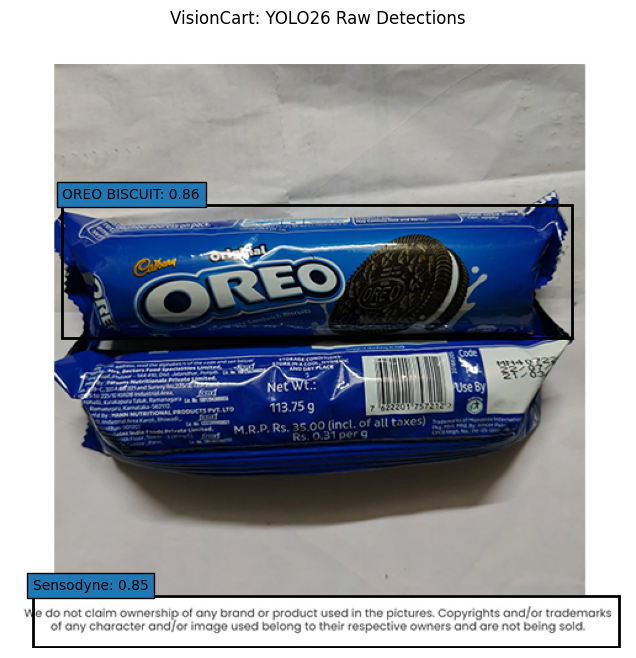

Image dimensions: (500, 500)


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

image_path = "/content/Oreo-biscuits.jpg"
image = Image.open(image_path).convert("RGB")

result = oreo_results[0]

plt.figure(figsize=(12, 8))
plt.imshow(image)

ax = plt.gca()

for box in result.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = result.names[class_id]

    rectangle = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        max(0, y1 - 5),
        f"{class_name}: {confidence:.2f}",
        fontsize=10,
        bbox=dict()
    )

plt.title("VisionCart: YOLO26 Raw Detections")
plt.axis("off")
plt.show()

print("Image dimensions:", image.size)

In [ ]:
from qwen_vl_utils import process_vision_info
import torch

def verify_with_full_context(image_path, crop_path, yolo_class):
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image_path
                },
                {
                    "type": "image",
                    "image": crop_path
                },
                {
                    "type": "text",
                    "text": f"""
You are verifying an object-detection result for a grocery inventory system.

Image 1: The complete original scene.
Image 2: The region predicted by YOLO.

YOLO predicted class: {yolo_class}

Allowed classes:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

Examine both images carefully.

IMPORTANT RULES:
1. Verify whether the predicted class corresponds to an actual,
   recognizable physical product in the original scene.
2. Printed disclaimer text, copyright notices, logos in unrelated text,
   and background markings are not separate products.
3. Do not infer a product merely from words appearing in a disclaimer.
4. If the highlighted region is only text or background, reject it.
5. Accept only when the predicted product is visually supported.

Return exactly:

Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <short explanation>
"""
                }
            ]
        }
    ]

    prompt_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt_text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    trimmed = [
        out[len(inp):]
        for inp, out in zip(inputs.input_ids, generated_ids)
    ]

    return processor.batch_decode(
        trimmed,
        skip_special_tokens=True
    )[0]


# Test the false Sensodyne detection
answer = verify_with_full_context(
    image_path="/content/Oreo-biscuits.jpg",
    crop_path="/content/oreo_yolo_crop_1.jpg",
    yolo_class="Sensodyne"
)

print(answer)

Product: OREO BISCUIT
Decision: ACCEPT
Reason: The highlighted region in Image 2 clearly shows the blue packaging of an Oreo biscuit, which is visually identifiable and matches the allowed class "OREO BISCUIT".


In [ ]:
for i, box in enumerate(oreo_results[0].boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    width = x2 - x1
    height = y2 - y1
    aspect_ratio = width / max(height, 1)

    class_name = oreo_results[0].names[int(box.cls[0])]
    confidence = float(box.conf[0])

    print(f"\nDetection: {class_name}")
    print(f"Confidence: {confidence:.3f}")
    print(f"Width: {width}px")
    print(f"Height: {height}px")
    print(f"Aspect ratio: {aspect_ratio:.2f}:1")

    if aspect_ratio > 5:
        print("Warning: unusually thin detection; send for contextual verification.")
    else:
        print("Geometry: no extreme aspect-ratio warning.")


Detection: OREO BISCUIT
Confidence: 0.857
Width: 414px
Height: 108px
Aspect ratio: 3.83:1
Geometry: no extreme aspect-ratio warning.

Detection: Sensodyne
Confidence: 0.850
Width: 476px
Height: 42px
Aspect ratio: 11.33:1


In [ ]:
def analyze_detection_geometry(box):
    """
    Measure a YOLO detection and flag suspiciously thin boxes.
    Does not automatically reject any detection.
    """

    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    width = max(1, x2 - x1)
    height = max(1, y2 - y1)

    aspect_ratio = width / height
    area = width * height

    suspicious = aspect_ratio > 5 or aspect_ratio < 0.2

    return {
        "bbox": [x1, y1, x2, y2],
        "width": width,
        "height": height,
        "area": area,
        "aspect_ratio": round(aspect_ratio, 2),
        "suspicious_geometry": suspicious
    }


# Test on the Oreo image
for box in oreo_results[0].boxes:
    class_name = oreo_results[0].names[int(box.cls[0])]
    geometry = analyze_detection_geometry(box)

    print(f"\nClass: {class_name}")
    print(f"Aspect ratio: {geometry['aspect_ratio']}:1")
    print(f"Suspicious geometry: {geometry['suspicious_geometry']}")



Class: OREO BISCUIT
Aspect ratio: 3.83:1
Suspicious geometry: False

Class: Sensodyne
Aspect ratio: 11.33:1
Suspicious geometry: True


verification version 2

In [ ]:
import re
import torch
from PIL import Image
from qwen_vl_utils import process_vision_info


def visioncart_verify_v2(
    image_path,
    yolo_conf=0.25,
    imgsz=640,
    context_scale=3.0,
    suspicious_ratio=5.0
):
    image = Image.open(image_path).convert("RGB")
    image_width, image_height = image.size

    results = yolo_model.predict(
        source=image_path,
        conf=yolo_conf,
        imgsz=imgsz,
        verbose=False
    )

    result = results[0]
    verified_detections = []

    print(f"Image: {image_path} ({image_width} x {image_height})")
    print(f"YOLO detections: {len(result.boxes)}")

    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        yolo_class = result.names[int(box.cls[0])]
        yolo_confidence = float(box.conf[0])

        width = max(1, x2 - x1)
        height = max(1, y2 - y1)
        aspect_ratio = width / height

        suspicious = (
            aspect_ratio > suspicious_ratio
            or aspect_ratio < 1 / suspicious_ratio
        )

        # Expand the bounding box to include surrounding context.
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        ex1 = max(0, int(cx - width * context_scale / 2))
        ey1 = max(0, int(cy - height * context_scale / 2))
        ex2 = min(image_width, int(cx + width * context_scale / 2))
        ey2 = min(image_height, int(cy + height * context_scale / 2))

        crop_path = f"/content/visioncart_v2_crop_{i}.jpg"
        image.crop((ex1, ey1, ex2, ey2)).save(crop_path)

        geometry_note = (
            "WARNING: The detected box has unusually thin geometry. "
            "It may contain text or background rather than a product. "
            "Check carefully."
            if suspicious else
            "The box does not have an extreme aspect ratio."
        )

        prompt = f"""
You are verifying a grocery-product detection.

Image 1 is the original image.
Image 2 is the expanded region around the detection.

YOLO predicted: {yolo_class}
YOLO confidence: {yolo_confidence:.3f}
Box aspect ratio: {aspect_ratio:.2f}
Geometry assessment: {geometry_note}

Allowed classes:
- Maggi
- OREO BISCUIT
- Sensodyne
- Yippee
- NONE

Accept the prediction only if the same physical product is clearly
recognizable in the original scene and the expanded region.

Printed disclaimers, copyright notices, background text, or partial
letters are not separate products. Do not infer product identity from
text alone. If uncertain, reject the detection.

Return exactly:
Product: <one allowed class>
Decision: ACCEPT or REJECT
Reason: <brief explanation>
"""

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image_path},
                {"type": "image", "image": crop_path},
                {"type": "text", "text": prompt}
            ]
        }]

        chat_text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        image_inputs, video_inputs = process_vision_info(messages)

        inputs = processor(
            text=[chat_text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt"
        ).to(model.device)

        with torch.inference_mode():
            generated = model.generate(
                **inputs,
                max_new_tokens=100,
                do_sample=False
            )

        trimmed = [
            out_ids[len(in_ids):]
            for in_ids, out_ids in zip(inputs.input_ids, generated)
        ]

        answer = processor.batch_decode(
            trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()

        product_match = re.search(
            r"Product:\s*(Maggi|OREO BISCUIT|Sensodyne|Yippee|NONE)",
            answer,
            re.IGNORECASE
        )
        decision_match = re.search(
            r"Decision:\s*(ACCEPT|REJECT)",
            answer,
            re.IGNORECASE
        )

        qwen_class = (
            product_match.group(1).upper()
            if product_match else "UNKNOWN"
        )

        normalized_yolo = yolo_class.upper()

        accepted = (
            decision_match is not None
            and decision_match.group(1).upper() == "ACCEPT"
            and qwen_class == normalized_yolo
        )

        detection = {
            "class": yolo_class,
            "yolo_confidence": round(yolo_confidence, 4),
            "qwen_class": qwen_class,
            "accepted": accepted,
            "suspicious_geometry": suspicious,
            "aspect_ratio": round(aspect_ratio, 2),
            "bbox": [x1, y1, x2, y2],
            "qwen_response": answer
        }

        print(f"\nDetection {i + 1}: {yolo_class}")
        print(f"  YOLO confidence: {yolo_confidence:.3f}")
        print(f"  Aspect ratio: {aspect_ratio:.2f}")
        print(f"  Suspicious geometry: {suspicious}")
        print(f"  Qwen class: {qwen_class}")
        print(f"  Accepted: {accepted}")
        print(f"  Qwen response: {answer}")

        if accepted:
            verified_detections.append(detection)

    print("\nFINAL VERIFIED DETECTIONS:")
    if verified_detections:
        for detection in verified_detections:
            print(
                f"{detection['class']} "
                f"(YOLO confidence: {detection['yolo_confidence']:.3f})"
            )
    else:
        print("No detections passed verification.")

    return verified_detections


print("VisionCart v2 is ready.")

VisionCart v2 is ready.


In [ ]:
oreo_final = visioncart_verify_v2("/content/Oreo-biscuits.jpg")


Image: /content/Oreo-biscuits.jpg (500 x 500)
YOLO detections: 2

Detection 1: OREO BISCUIT
  YOLO confidence: 0.857
  Aspect ratio: 3.83
  Suspicious geometry: False
  Qwen class: OREO BISCUIT
  Accepted: True
  Qwen response: Product: OREO BISCUIT
Decision: ACCEPT
Reason: The physical product, a Cadbury Original Oreo biscuit package, is clearly recognizable in both the original image and the expanded region. The packaging design, including the blue wrapper, the Oreo logo, and the image of the biscuit, is consistent across both views. The YOLO prediction is accurate and not based on text alone.

Detection 2: Sensodyne
  YOLO confidence: 0.850
  Aspect ratio: 11.33
  Suspicious geometry: True
  Qwen class: OREO BISCUIT
  Accepted: False
  Qwen response: Product: OREO BISCUIT
Decision: ACCEPT
Reason: The expanded region clearly shows the blue packaging of an OREO biscuit pack, matching the product in the original image. The text and branding are visible, confirming it is an OREO BISCUIT